# Issue #8 — Test Prediction-Based Roll Timing

Test whether predicted ZN liquidity crossover timing identifies a more cost-effective time to roll.

**This notebook uses only project data already created by earlier notebooks. It downloads nothing.**

Inputs:
- `zn_standardized_roll_panel.parquet` from Issue #14 / Step 7;
- `zn_early_indicator_panel.parquet` from `06_develop_early_indicators.ipynb`;
- `zn_crossover_events.parquet` from `05_define_crossover.ipynb`.

The early-indicator notebook already created the predictor variables, so they are not rebuilt here.

Because the project has no observed bid/ask quotes, transaction costs cannot be measured directly. We therefore compare roll schedules using the two cost proxies already derived from the existing daily calendar-spread OHLC:

1. `spread_roll_half_spread_cost_est` — a Roll-style implied half-spread estimate where identified;
2. `spread_half_range_cost_proxy` — half the daily calendar-spread high-low range as a deliberately conservative robustness proxy.

This distinction matters. The analysis tests whether the timing rule finds **cheaper-looking execution conditions in the available data**; it does not claim to recover true slippage for a specific order size.

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = next(
    (p for p in (Path.cwd(), Path.cwd().parent)
     if (p / 'data' / 'processed' / 'zn_standardized_roll_panel.parquet').exists()),
    None
)
if project_root is None:
    raise FileNotFoundError(
        f"Could not locate standardized panel from {Path.cwd()}. "
        "Run 07_build_standardized_roll_panel.ipynb first."
    )

processed_dir = project_root / 'data' / 'processed'

standard = pd.read_parquet(processed_dir / 'zn_standardized_roll_panel.parquet')
early = pd.read_parquet(processed_dir / 'zn_early_indicator_panel.parquet')
events = pd.read_parquet(processed_dir / 'zn_crossover_events.parquet')

for df in (standard, early):
    df['date'] = pd.to_datetime(df['date'])
events['volume_crossover_date'] = pd.to_datetime(events['volume_crossover_date'])

required_standard = {
    'roll_id', 'date', 'bdays_to_fnd', 'next_volume_share', 'next_oi_share',
    'spread_volume', 'spread_volume_share',
    'spread_roll_half_spread_cost_est', 'spread_half_range_cost_proxy'
}
missing = required_standard - set(standard.columns)
if missing:
    raise ValueError(f"Standardized panel missing columns: {sorted(missing)}")

required_early = {
    'roll_id', 'date', 'bdays_to_fnd',
    'next_volume_share', 'next_volume_share_change_3d',
    'next_volume_share_change_5d', 'next_oi_share',
    'next_oi_share_change_3d', 'log_spread_volume'
}
missing = required_early - set(early.columns)
if missing:
    raise ValueError(f"Early-indicator panel missing columns: {sorted(missing)}")

print(f"Standardized panel: {standard['roll_id'].nunique()} rolls")
print(f"Early-indicator panel: {early['roll_id'].nunique()} rolls")
print(f"Crossover events: {len(events)} rolls")


Standardized panel: 27 rolls
Early-indicator panel: 27 rolls
Crossover events: 27 rolls


## 1. Define an ex-ante prediction problem

To avoid using repeated roll-days as if they were independent observations, make one crossover-timing prediction per roll.

For each roll, use the indicator values available approximately **10 panel business days before FND**. The target is the observed volume-crossover day relative to FND.

Evaluation is **expanding-window out of sample**:
- each test roll is predicted using only earlier rolls;
- no later roll is allowed into its training sample;
- at least eight completed historical rolls are required before producing a prediction.

This is deliberately stricter than randomly splitting daily rows from the same rolls.

In [10]:
DECISION_BDAY = -10
MIN_TRAIN_ROLLS = 8

FEATURES = [
    'next_volume_share',
    'next_volume_share_change_3d',
    'next_volume_share_change_5d',
    'next_oi_share',
    'next_oi_share_change_3d',
    'log_spread_volume',
]

# Select the available row nearest the ex-ante decision day for each roll.
decision = early.copy()
decision['decision_distance'] = (decision['bdays_to_fnd'] - DECISION_BDAY).abs()
decision = (
    decision.sort_values(['roll_id', 'decision_distance', 'date'])
    .groupby('roll_id', as_index=False)
    .first()
)

decision = decision.merge(
    events[[
        'roll_id', 'volume_crossover_observed',
        'volume_crossover_date', 'volume_crossover_bdays_to_fnd'
    ]],
    on='roll_id', how='left', validate='one_to_one'
)

# Chronological ordering for expanding-window evaluation.
first_dates = (
    standard.groupby('roll_id', as_index=False)['date']
    .min().rename(columns={'date': 'roll_start_date'})
)
decision = decision.merge(first_dates, on='roll_id', how='left', validate='one_to_one')
decision = decision.sort_values('roll_start_date').reset_index(drop=True)

display(decision[[
    'roll_id', 'date', 'bdays_to_fnd',
    'volume_crossover_bdays_to_fnd'
] + FEATURES].head(12))


,roll_id,date,bdays_to_fnd,volume_crossover_bdays_to_fnd,next_volume_share,next_volume_share_change_3d,next_volume_share_change_5d,next_oi_share,next_oi_share_change_3d,log_spread_volume
0,ZNH0->ZNM0,2020-02-17,-10,-1,0.007514,0.004998,0.002323,0.058916,0.007265,8.452761
1,ZNM0->ZNU0,2020-05-18,-10,-1,0.008399,0.003333,0.004368,0.046826,0.005705,11.264772
2,ZNU0->ZNZ0,2020-08-19,-10,-2,0.008217,0.007912,0.006999,0.029304,0.008433,11.021919
3,ZNZ0->ZNH1,2020-11-18,-10,-2,0.006785,0.004720,0.005429,0.018299,0.005281,11.925770
4,ZNH1->ZNM1,2021-02-15,-10,-1,0.003873,0.000743,0.001308,0.035506,0.011305,9.665991
5,ZNM1->ZNU1,2021-05-19,-10,-3,0.022533,0.018569,0.020447,0.029361,0.010502,11.400865
6,ZNU1->ZNZ1,2021-08-19,-10,-2,0.008317,0.004110,0.006484,0.023190,0.014994,10.615334
7,ZNZ1->ZNH2,2021-11-18,-10,-2,0.016389,0.011972,0.014887,0.028924,0.012194,11.480609
8,ZNH2->ZNM2,2022-02-16,-10,-2,0.012401,0.009294,0.010625,0.031645,0.006437,10.511730
9,ZNM2->ZNU2,2022-05-19,-10,-3,0.019972,0.014101,0.015752,0.037982,0.015507,11.863103


## 2. Predict crossover timing using only prior rolls

A small linear model is sufficient for the test here; the objective is not to maximize in-sample fit.

For every test roll:
- feature missing values are filled using **training-sample medians only**;
- features are standardized using **training-sample** means and standard deviations only;
- ordinary least squares is fitted on the prior rolls;
- the predicted crossover day is clipped to the interval from the decision day through FND.

We also construct a harder-to-beat simple benchmark: the median crossover day observed in prior rolls. If the feature model cannot beat that benchmark, the extra prediction machinery is not useful.

In [11]:
prediction_rows = []

for i in range(len(decision)):
    test = decision.iloc[i]
    train = decision.iloc[:i].copy()

    train = train.loc[
        train['volume_crossover_observed'].fillna(False)
        & train['volume_crossover_bdays_to_fnd'].notna()
    ]

    if len(train) < MIN_TRAIN_ROLLS:
        continue

    # Keep features that have enough historical observations and nonzero variation.
    active = []
    medians = {}
    means = {}
    stds = {}

    X_train_cols = []
    x_test_vals = []

    for feature in FEATURES:
        series = pd.to_numeric(train[feature], errors='coerce')
        if series.notna().sum() < max(5, MIN_TRAIN_ROLLS // 2):
            continue

        med = series.median()
        filled = series.fillna(med)
        sd = filled.std(ddof=0)
        if not np.isfinite(sd) or sd == 0:
            continue

        mu = filled.mean()

        active.append(feature)
        medians[feature] = med
        means[feature] = mu
        stds[feature] = sd
        X_train_cols.append(((filled - mu) / sd).to_numpy())

        test_val = pd.to_numeric(pd.Series([test[feature]]), errors='coerce').iloc[0]
        if pd.isna(test_val):
            test_val = med
        x_test_vals.append((test_val - mu) / sd)

    if len(active) == 0:
        continue

    X = np.column_stack(X_train_cols)
    X = np.column_stack([np.ones(len(X)), X])

    y = train['volume_crossover_bdays_to_fnd'].astype(float).to_numpy()

    # OLS via least squares; the small feature set is intentional.
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)

    x_test = np.array([1.0] + x_test_vals)
    raw_pred = float(x_test @ beta)

    # The strategy cannot choose a day before the information date,
    # and this project is concerned with rolling no later than FND.
    predicted_bday = int(np.rint(np.clip(raw_pred, test['bdays_to_fnd'], 0)))

    historical_median = int(np.rint(
        train['volume_crossover_bdays_to_fnd'].median()
    ))

    prediction_rows.append({
        'roll_id': test['roll_id'],
        'decision_date': test['date'],
        'decision_bday': int(test['bdays_to_fnd']),
        'training_rolls': len(train),
        'features_used': ', '.join(active),
        'raw_predicted_crossover_bday': raw_pred,
        'predicted_crossover_bday': predicted_bday,
        'historical_median_crossover_bday': historical_median,
        'actual_crossover_bday': test['volume_crossover_bdays_to_fnd'],
        'actual_crossover_date': test['volume_crossover_date'],
    })

predictions = pd.DataFrame(prediction_rows)

if predictions.empty:
    raise ValueError("No out-of-sample predictions were produced.")

predictions['prediction_error_bdays'] = (
    predictions['predicted_crossover_bday']
    - predictions['actual_crossover_bday']
)
predictions['historical_median_error_bdays'] = (
    predictions['historical_median_crossover_bday']
    - predictions['actual_crossover_bday']
)

display(predictions)

print("Prediction MAE, business days:",
      predictions['prediction_error_bdays'].abs().mean())
print("Historical-median MAE, business days:",
      predictions['historical_median_error_bdays'].abs().mean())


,roll_id,decision_date,decision_bday,training_rolls,features_used,raw_predicted_crossover_bday,predicted_crossover_bday,historical_median_crossover_bday,actual_crossover_bday,actual_crossover_date,prediction_error_bdays,historical_median_error_bdays
0,ZNH2->ZNM2,2022-02-16,-10,8,"next_volume_share, next_volume_share_change_3d...",-1.169419,-1,-2,-2,2022-02-25,1,0
1,ZNM2->ZNU2,2022-05-19,-10,9,"next_volume_share, next_volume_share_change_3d...",-2.559962,-3,-2,-3,2022-05-27,0,1
2,ZNU2->ZNZ2,2022-08-19,-10,10,"next_volume_share, next_volume_share_change_3d...",-1.909949,-2,-2,-2,2022-08-29,0,0
3,ZNZ2->ZNH3,2022-11-18,-10,11,"next_volume_share, next_volume_share_change_3d...",-9.060992,-9,-2,-2,2022-11-28,-7,0
4,ZNH3->ZNM3,2023-02-16,-10,12,"next_volume_share, next_volume_share_change_3d...",-2.516338,-3,-2,-2,2023-02-26,-1,0
5,ZNM3->ZNU3,2023-05-19,-10,13,"next_volume_share, next_volume_share_change_3d...",-4.847499,-5,-2,-2,2023-05-29,-3,0
6,ZNU3->ZNZ3,2023-08-20,-10,14,"next_volume_share, next_volume_share_change_3d...",-2.337855,-2,-2,-2,2023-08-29,0,0
7,ZNZ3->ZNH4,2023-11-19,-10,15,"next_volume_share, next_volume_share_change_3d...",-2.343590,-2,-2,-2,2023-11-28,0,0
8,ZNH4->ZNM4,2024-02-18,-10,16,"next_volume_share, next_volume_share_change_3d...",-1.523473,-2,-2,-1,2024-02-28,-1,-1
9,ZNM4->ZNU4,2024-05-20,-10,17,"next_volume_share, next_volume_share_change_3d...",-2.607323,-3,-2,-2,2024-05-29,-1,0


Prediction MAE, business days: 1.0
Historical-median MAE, business days: 0.2631578947368421


## Prediction Results

The prediction model does not improve on the simple historical timing rule. Across the 19 out-of-sample rolls, the predicted crossover has a mean absolute error of 1.00 relative days, compared with only 0.26 for the historical-median crossover rule.

This is an important result rather than a failure of the test. Liquidity crossover in this sample is highly concentrated around the same relative date, so a simple rule based on previous rolls is difficult to improve upon. The additional volume, open-interest, and spread-activity signals occasionally move the predicted date substantially away from the realized crossover and increase forecast error.

For this sample, predicting the exact crossover from these features adds little value relative to simply knowing when crossover normally occurs.

## 3. Map each timing rule to an actual available roll-day observation

Compare five implementable schedules:

- **prediction_based** — the model's predicted crossover day;
- **historical_median** — median crossover timing from prior rolls only;
- **fixed_-5** — five business days before FND;
- **fixed_-3** — three business days before FND;
- **fixed_-1** — one business day before FND.

`hindsight_actual_crossover` is included only as a diagnostic. It is not an implementable benchmark because it uses the realized event itself.

In [12]:
def nearest_roll_row(grp, target_bday):
    grp = grp.copy()
    grp['distance_to_target'] = (grp['bdays_to_fnd'] - target_bday).abs()
    # If equally close, choose the earlier date to avoid silently looking forward.
    return grp.sort_values(['distance_to_target', 'date']).iloc[0]

eval_rows = []

for _, pred in predictions.iterrows():
    grp = standard.loc[standard['roll_id'] == pred['roll_id']].sort_values('date')
    if grp.empty:
        continue

    schedules = {
        'prediction_based': pred['predicted_crossover_bday'],
        'historical_median': pred['historical_median_crossover_bday'],
        'fixed_-5': -5,
        'fixed_-3': -3,
        'fixed_-1': -1,
        'hindsight_actual_crossover': pred['actual_crossover_bday'],
    }

    for strategy, target_bday in schedules.items():
        if pd.isna(target_bday):
            continue

        row = nearest_roll_row(grp, float(target_bday))
        eval_rows.append({
            'roll_id': pred['roll_id'],
            'strategy': strategy,
            'target_bday': float(target_bday),
            'selected_bday': row['bdays_to_fnd'],
            'selected_date': row['date'],
            'spread_roll_half_spread_cost_est': row['spread_roll_half_spread_cost_est'],
            'spread_half_range_cost_proxy': row['spread_half_range_cost_proxy'],
            'spread_volume': row['spread_volume'],
            'spread_volume_share': row['spread_volume_share'],
            'next_volume_share': row['next_volume_share'],
            'next_oi_share': row['next_oi_share'],
        })

evaluation = pd.DataFrame(eval_rows)
display(evaluation.head(18))


,roll_id,strategy,target_bday,selected_bday,selected_date,spread_roll_half_spread_cost_est,spread_half_range_cost_proxy,spread_volume,spread_volume_share,next_volume_share,next_oi_share
0,ZNH2->ZNM2,prediction_based,-1.0,-1,2022-02-27,0.009497,0.023438,8639,0.074429,0.948321,0.968038
1,ZNH2->ZNM2,historical_median,-2.0,-2,2022-02-25,0.008194,0.031250,351361,0.164367,0.750988,0.905433
2,ZNH2->ZNM2,fixed_-5,-5.0,-5,2022-02-22,NaN,0.031250,1883135,0.475109,0.121100,0.100658
3,ZNH2->ZNM2,fixed_-3,-3.0,-3,2022-02-24,0.006639,0.035156,1534673,0.300720,0.400970,0.698776
4,ZNH2->ZNM2,fixed_-1,-1.0,-1,2022-02-27,0.009497,0.023438,8639,0.074429,0.948321,0.968038
5,ZNH2->ZNM2,hindsight_actual_crossover,-2.0,-2,2022-02-25,0.008194,0.031250,351361,0.164367,0.750988,0.905433
6,ZNM2->ZNU2,prediction_based,-3.0,-3,2022-05-27,0.008715,0.046875,273304,0.204550,0.672633,0.916388
7,ZNM2->ZNU2,historical_median,-2.0,-2,2022-05-29,0.006988,0.003906,22,0.002708,0.789311,0.972528
8,ZNM2->ZNU2,fixed_-5,-5.0,-5,2022-05-25,0.008715,0.023438,2109845,0.564333,0.295871,0.452946
9,ZNM2->ZNU2,fixed_-3,-3.0,-3,2022-05-27,0.008715,0.046875,273304,0.204550,0.672633,0.916388


## 4. Compare transaction-cost proxies

Do not judge the strategy only by average cost. *Dynamic Hedging* emphasizes that liquidity losses and forced execution can be nonlinear and badly represented by a single central estimate.

Accordingly, report:
- coverage;
- median and mean;
- 90th percentile;
- worst observed cost;
- spread volume at the chosen date.

A timing rule that slightly improves the mean but creates a worse tail is not obviously better.

In [13]:
def q90(x):
    return x.quantile(0.90)

summary = (
    evaluation.groupby('strategy')
    .agg(
        rolls=('roll_id', 'nunique'),
        roll_spread_estimate_observations=('spread_roll_half_spread_cost_est', 'count'),
        roll_spread_cost_median=('spread_roll_half_spread_cost_est', 'median'),
        roll_spread_cost_mean=('spread_roll_half_spread_cost_est', 'mean'),
        roll_spread_cost_p90=('spread_roll_half_spread_cost_est', q90),
        roll_spread_cost_worst=('spread_roll_half_spread_cost_est', 'max'),
        range_proxy_observations=('spread_half_range_cost_proxy', 'count'),
        range_proxy_median=('spread_half_range_cost_proxy', 'median'),
        range_proxy_mean=('spread_half_range_cost_proxy', 'mean'),
        range_proxy_p90=('spread_half_range_cost_proxy', q90),
        range_proxy_worst=('spread_half_range_cost_proxy', 'max'),
        median_spread_volume=('spread_volume', 'median'),
        median_spread_volume_share=('spread_volume_share', 'median'),
        median_next_volume_share=('next_volume_share', 'median'),
    )
    .sort_index()
)

display(summary)


,rolls,roll_spread_estimate_observations,roll_spread_cost_median,roll_spread_cost_mean,roll_spread_cost_p90,roll_spread_cost_worst,range_proxy_observations,range_proxy_median,range_proxy_mean,range_proxy_p90,range_proxy_worst,median_spread_volume,median_spread_volume_share,median_next_volume_share
strategy,,,,,,,,,,,,,,
fixed_-1,19,14,0.006025,0.007157,0.011733,0.020339,19,0.019531,0.019120,0.028125,0.035156,205591.0,0.114763,0.914298
fixed_-3,19,16,0.006124,0.006527,0.009500,0.018266,19,0.015625,0.016242,0.028906,0.046875,2184699.0,0.518057,0.394996
fixed_-5,19,13,0.006484,0.007422,0.010872,0.021028,19,0.007812,0.011308,0.023438,0.031250,125152.0,0.370959,0.196181
hindsight_actual_crossover,19,14,0.007130,0.006975,0.009745,0.019295,19,0.019531,0.021793,0.037500,0.050781,1075627.0,0.366348,0.652034
historical_median,19,13,0.007273,0.007160,0.009845,0.019295,19,0.019531,0.020765,0.032031,0.050781,1031545.0,0.328404,0.655033
prediction_based,19,14,0.004142,0.006195,0.009263,0.019295,19,0.019531,0.019737,0.031250,0.050781,1035115.0,0.366348,0.620040


## 5. Paired comparison against each benchmark

The cleanest comparison is within the same roll. For each benchmark, subtract its cost from the prediction-based cost.

- negative difference = prediction-based timing was cheaper;
- positive difference = benchmark was cheaper.

We do this separately for the Roll-style half-spread estimate and the high-low range proxy.

In [14]:
BENCHMARKS = ['historical_median', 'fixed_-5', 'fixed_-3', 'fixed_-1']

def paired_comparison(metric):
    pred = (
        evaluation.loc[evaluation['strategy'] == 'prediction_based',
                       ['roll_id', metric]]
        .rename(columns={metric: 'predicted_cost'})
    )

    rows = []
    for benchmark in BENCHMARKS:
        bench = (
            evaluation.loc[evaluation['strategy'] == benchmark,
                           ['roll_id', metric]]
            .rename(columns={metric: 'benchmark_cost'})
        )
        paired = pred.merge(bench, on='roll_id', how='inner').dropna()
        paired['difference'] = paired['predicted_cost'] - paired['benchmark_cost']

        rows.append({
            'metric': metric,
            'benchmark': benchmark,
            'paired_rolls': len(paired),
            'median_pred_minus_benchmark': paired['difference'].median(),
            'mean_pred_minus_benchmark': paired['difference'].mean(),
            'prediction_cheaper_fraction': (
                (paired['difference'] < 0).mean() if len(paired) else np.nan
            ),
            'prediction_not_worse_fraction': (
                (paired['difference'] <= 0).mean() if len(paired) else np.nan
            ),
            'worst_pred_minus_benchmark': (
                paired['difference'].max() if len(paired) else np.nan
            ),
        })

    return pd.DataFrame(rows)

paired_roll = paired_comparison('spread_roll_half_spread_cost_est')
paired_range = paired_comparison('spread_half_range_cost_proxy')

paired_results = pd.concat([paired_roll, paired_range], ignore_index=True)
display(paired_results)


,metric,benchmark,paired_rolls,median_pred_minus_benchmark,mean_pred_minus_benchmark,prediction_cheaper_fraction,prediction_not_worse_fraction,worst_pred_minus_benchmark
0,spread_roll_half_spread_cost_est,historical_median,13,0.000000,-0.000667,0.307692,0.769231,0.001943
1,spread_roll_half_spread_cost_est,fixed_-5,10,-0.000854,-0.001248,0.600000,0.800000,0.001942
2,spread_roll_half_spread_cost_est,fixed_-3,14,0.000000,-0.000521,0.285714,0.714286,0.002858
3,spread_roll_half_spread_cost_est,fixed_-1,13,-0.000617,-0.000795,0.615385,0.692308,0.006698
4,spread_half_range_cost_proxy,historical_median,19,0.000000,-0.001028,0.368421,0.894737,0.042969
5,spread_half_range_cost_proxy,fixed_-5,19,0.007812,0.008429,0.210526,0.263158,0.031250
6,spread_half_range_cost_proxy,fixed_-3,19,0.000000,0.003495,0.210526,0.736842,0.042969
7,spread_half_range_cost_proxy,fixed_-1,19,0.000000,0.000617,0.368421,0.631579,0.031250


## 6. Inspect timing accuracy and execution implications

The timing model is useful only if the execution results survive comparison with simple schedules.

Interpretation should therefore separate two questions:

1. **Prediction:** Does the early-indicator model forecast crossover timing more accurately than the historical-median rule?
2. **Execution:** On the dates it selects, are the available transaction-cost proxies lower without materially worse tail outcomes?

If the answer to (1) is yes but (2) is no, better crossover prediction did not translate into a better roll.
If the cost result exists only for one proxy or only in the mean, the evidence is weak.

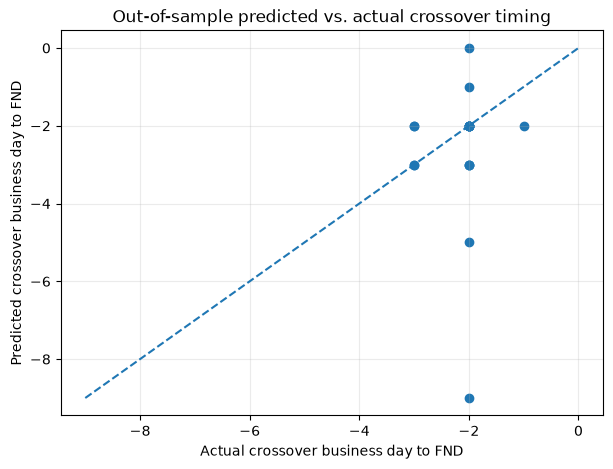

,roll_id,training_rolls,predicted_crossover_bday,actual_crossover_bday,prediction_error_bdays,historical_median_crossover_bday,historical_median_error_bdays
0,ZNH2->ZNM2,8,-1,-2,1,-2,0
1,ZNM2->ZNU2,9,-3,-3,0,-2,1
2,ZNU2->ZNZ2,10,-2,-2,0,-2,0
3,ZNZ2->ZNH3,11,-9,-2,-7,-2,0
4,ZNH3->ZNM3,12,-3,-2,-1,-2,0
5,ZNM3->ZNU3,13,-5,-2,-3,-2,0
6,ZNU3->ZNZ3,14,-2,-2,0,-2,0
7,ZNZ3->ZNH4,15,-2,-2,0,-2,0
8,ZNH4->ZNM4,16,-2,-1,-1,-2,-1
9,ZNM4->ZNU4,17,-3,-2,-1,-2,0


In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    predictions['actual_crossover_bday'],
    predictions['predicted_crossover_bday']
)
lo = min(
    predictions['actual_crossover_bday'].min(),
    predictions['predicted_crossover_bday'].min()
)
hi = max(
    predictions['actual_crossover_bday'].max(),
    predictions['predicted_crossover_bday'].max()
)
ax.plot([lo, hi], [lo, hi], linestyle='--')
ax.set(
    xlabel='Actual crossover business day to FND',
    ylabel='Predicted crossover business day to FND',
    title='Out-of-sample predicted vs. actual crossover timing'
)
ax.grid(alpha=0.25)
plt.show()

display(predictions[[
    'roll_id', 'training_rolls',
    'predicted_crossover_bday', 'actual_crossover_bday',
    'prediction_error_bdays',
    'historical_median_crossover_bday',
    'historical_median_error_bdays'
]])


## Conclusion

The original hypothesis was that early indicators of liquidity migration might allow us to anticipate crossover and roll more cheaply than a fixed schedule. In this sample, the crossover itself is sufficiently regular that a historical-median rule predicts it better than the fitted model.

More importantly, better alignment with liquidity crossover does not translate consistently into lower estimated execution cost. One cost proxy favors the prediction-based strategy, while the more broadly available range-based proxy favors rolling earlier. We therefore find no robust evidence that prediction-based crossover timing dominates a simple conventional roll schedule.

The practical implication is that liquidity should be treated as an execution constraint rather than a single threshold. Waiting until the next contract has clearly become dominant may improve available activity, but it does not necessarily produce the lowest cost of moving the position.

In [16]:
pred_path = processed_dir / 'zn_roll_timing_predictions.parquet'
eval_path = processed_dir / 'zn_roll_timing_cost_comparison.parquet'
summary_path = processed_dir / 'zn_roll_timing_cost_summary.parquet'

predictions.to_parquet(pred_path, index=False)
evaluation.to_parquet(eval_path, index=False)
summary.reset_index().to_parquet(summary_path, index=False)
